# Semantic search from scratch

```
articles -> chunks -> BM25 index (exact words)       -> ranked chunks
                   -> dense index (vectors)          -> ranked chunks
                                  fusion (hybrid)    -> ranked chunks -> (optional) cross-encoder rerank
```

**Questions explored**
1. How does chunk size change what gets retrieved?
2. Where do keyword search (BM25) and vector search disagree, and why?
3. Does combining them help, and by how much? Measured, not assumed, with two evaluations: topic queries (relevance from Reuters labels) and *headline to article* retrieval (a known-item task).

The dense part uses **LSA vectors** so the notebook runs anywhere. 
Optional cells swap in Sentence-Transformers, FAISS and a cross-encoder reranker (`%pip install sentence-transformers faiss-cpu`): the saved outputs come from an environment without them.

In [1]:
# %pip install sentence-transformers faiss-cpu   # optional sections only

# Libraries and setup

In [2]:
import re
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize

DATA_PATH = Path("classification_V1/reuters21578")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)

In [4]:
def parse_sgm_file(filepath):
    with open(filepath, "r", encoding="latin-1") as f:
        soup = BeautifulSoup(f.read(), "html.parser")
    return [{"id": r.get("newid"),
             "title": r.title.text.strip() if r.title else "",
             "body": r.body.text.strip() if r.body else "",
             "topics": [d.text for d in r.topics.find_all("d")] if r.topics else []}
            for r in soup.find_all("reuters")]

rows = []
for file in sorted(DATA_PATH.glob("*.sgm")):
    rows.extend(parse_sgm_file(file))
articles = pd.DataFrame(rows)
articles = articles[articles["body"].str.len() > 0].reset_index(drop=True)
# Every body ends with a "Reuter" sign-off plus a control character (\x03): noise for retrieval.
articles["body"] = articles["body"].str.replace(r"(?i)\s*reuter\W*$", "", regex=True)
print(f"{len(articles):,} articles with a body")
articles.head()

19,043 articles with a body


,id,title,body,topics
0,1,BAHIA COCOA REVIEW,"Showers continued throughout the week in\nthe Bahia cocoa zone, alleviating the drought since early\nJanua...",[cocoa]
1,2,STANDARD OIL <SRD> TO FORM FINANCIAL UNIT,Standard Oil Co and BP North America\nInc said they plan to form a venture to manage the money market\nbor...,[]
2,3,TEXAS COMMERCE BANCSHARES <TCB> FILES PLAN,Texas Commerce Bancshares Inc's Texas\nCommerce Bank-Houston said it filed an application with the\nComptr...,[]
3,4,TALKING POINT/BANKAMERICA <BAC> EQUITY OFFER,BankAmerica Corp is not under\npressure to act quickly on its proposed equity offering and\nwould do well ...,[]
4,5,NATIONAL AVERAGE PRICES FOR FARMER-OWNED RESERVE,The U.S. Agriculture Department\nreported the farmer-owned reserve national five-day average\nprice throug...,"[grain, wheat, corn, barley, oat, sorghum]"


# 1. Chunking

Retrieval returns *pieces* of documents. 
The chunker below splits on paragraph breaks first, then sentences, then words, and adds a small overlap so a fact cut at a boundary still appears whole in one chunk.

Only the **body** is indexed. 
Headlines are kept aside: section 6 uses them as queries.

In [6]:
SEPARATORS = ["\n\n", "\n", ". ", " "] # paragraphs, lines, sentences, words

def split_recursive(text, size, separators=SEPARATORS):
    if len(text) <= size:
        return [text]
    sep, rest = separators[0], separators[1:]
    pieces, current = [], ""
    for part in text.split(sep):
        candidate = f"{current}{sep}{part}" if current else part
        if len(candidate) <= size:
            current = candidate
            continue
        if current:
            pieces.append(current)
        if len(part) > size and rest:
            pieces.extend(split_recursive(part, size, rest))
            current = ""
        else:
            current = part[:size]
    if current:
        pieces.append(current)
    return pieces

def chunk_articles(articles, size=500, overlap=50):
    assert 0 <= overlap < size, "overlap must be smaller than the chunk size"
    out = []
    for row in articles.itertuples():
        body = re.sub(r"[ \t]+", " ", row.body)
        pieces = [p.strip() for p in split_recursive(body, size) if p.strip()]
        for i, piece in enumerate(pieces):
            text = (pieces[i - 1][-overlap:] + " " + piece) if (i and overlap) else piece
            out.append({"chunk_id": f"{row.id}-{i}", "article_id": row.id, "text": text.strip(), "topics": row.topics})
    return pd.DataFrame(out)

stats = {}
for size in [200, 500, 1000, 100_000]:
    c = chunk_articles(articles, size=size, overlap=min(50, size // 4))
    label = "whole article" if size == 100_000 else f"{size} chars"
    stats[label] = {"chunks": len(c), "chunks per article": round(len(c) / len(articles), 2), "median chars": int(c["text"].str.len().median())}
pd.DataFrame.from_dict(stats, orient="index")

,chunks,chunks per article,median chars
200 chars,95963,5.04,214
500 chars,41896,2.20,464
1000 chars,26555,1.39,556
whole article,19043,1.00,535


Reuters articles are short (median around 600 characters), so 500-character chunks keep most short stories in
one piece while splitting long ones. The effect of this choice on retrieval is measured in section 7.

In [11]:
chunks = chunk_articles(articles, size=500, overlap=50)
article_of = chunks["article_id"].to_numpy()
print(f"{len(chunks):,} chunks of up to 500 chars (+50 overlap)")
chunks.head(-5)

41,896 chunks of up to 500 chars (+50 overlap)


,chunk_id,article_id,text,topics
0,1-0,1,"Showers continued throughout the week in\nthe Bahia cocoa zone, alleviating the drought since early\nJanua...",[cocoa]
1,1-1,1,t 5.81 at the same stage last year. Again it seems that cocoa delivered earlier on consignment was include...,[cocoa]
2,1-2,1,e doubts as to how much of this cocoa would be fit for export as shippers are now experiencing dificulties...,[cocoa]
3,1-3,1,",750 to\n1,780 dlrs per tonne to ports to be named. New crop sales were also light and all to open ports w...",[cocoa]
4,1-4,1,"times New York Sept and Oct/Dec at 4,480 dlrs and 2.27 times New York Dec, Comissaria Smith said.\n Destin...",[cocoa]
...,...,...,...,...
41886,21575-1,21575,ts fell by 0.5 pct and imports dropped by 4.2\npct. Foreign trade in the nine months totalled 94.2 billion...,[ipi]
41887,21575-2,21575,"orbachev's drive to modernise the economy, special inspectors have the right to reject goods they consider...",[ipi]
41888,21575-3,21575,tion of the cooperative and private sectors of the economy has been an important part of the modernisation...,[ipi]
41889,21575-4,21575,which measures worker output over a given period. Pravda said there were 283.8 mln people in the Soviet Un...,[ipi]


# 2. Keyword search: BM25, built by hand

BM25 (Best Matching 25) is a ranking algorithm used in information retrieval systems to determine how relevant a document is to a given search query. 
It’s an improved version of the traditional TF-IDF (Term Frequency–Inverse Document Frequency) approach and is widely used in modern search engines and databases.
- It measures term frequency and document relevance more accurately
- It accounts for document length normalization, giving fair weight to all documents
- It is widely used in tools like Elasticsearch, Whoosh and Lucene
- It helps to deliver more relevant search results based on keyword matching and context

In simple terms, BM25 helps rank documents or web pages based on how well they match a user’s search terms making it a cornerstone of effective search and retrieval systems.

BM25 improves on raw TF-IDF in two ways that matter for search:
- **term frequency saturates** (parameter `k1`): the 10th occurrence of "oil" adds much less than the first
- **length normalisation** (parameter `b`): long chunks do not win just by containing more words

$$\text{score}(q, d) = \sum_{t \in q} \text{idf}(t) \cdot \frac{f_{t,d}\,(k_1+1)}{f_{t,d} + k_1\left(1 - b + b\frac{|d|}{\text{avgdl}}\right)}$$

Pre-computing the per-term weight of every chunk once turns scoring into a sparse matrix-vector product.

In [12]:
class BM25:
    def __init__(self, texts, k1=1.5, b=0.75):
        self.vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b")
        tf = self.vectorizer.fit_transform(texts).tocsc().astype(np.float64)   # chunks x terms
        n = tf.shape[0]
        doc_len = np.asarray(tf.sum(axis=1)).ravel()
        df = np.diff(tf.indptr)                                                # documents containing each term
        self.idf = np.log(1 + (n - df + 0.5) / (df + 0.5))
        tf = tf.tocoo()
        norm = k1 * (1 - b + b * doc_len[tf.row] / doc_len.mean())
        weights = tf.data * (k1 + 1) / (tf.data + norm) * self.idf[tf.col]
        self.matrix = sparse.csr_matrix((weights, (tf.row, tf.col)), shape=tf.shape)

    def scores(self, query):
        q = (self.vectorizer.transform([query]) > 0).astype(np.float64)       # each query term counted once
        return np.asarray(self.matrix @ q.T.toarray()).ravel()

t0 = time.time()
bm25 = BM25(chunks["text"].tolist())
print(f"BM25 index: {bm25.matrix.shape[0]:,} chunks x {bm25.matrix.shape[1]:,} terms, built in {time.time() - t0:.1f}s")

BM25 index: 41,896 chunks x 44,768 terms, built in 1.5s


Sanity check: recompute one chunk's score with a plain loop over the formula.

In [13]:
def bm25_by_hand(query, text, index, k1=1.5, b=0.75):
    vocab = index.vectorizer.vocabulary_
    analyzer = index.vectorizer.build_analyzer()
    words = analyzer(text)
    avgdl = np.mean([len(analyzer(t)) for t in chunks["text"]])
    score = 0.0
    for term in set(analyzer(query)):
        if term not in vocab:
            continue
        f = words.count(term)
        score += index.idf[vocab[term]] * f * (k1 + 1) / (f + k1 * (1 - b + b * len(words) / avgdl))
    return score

query = "oil tanker attacked in the gulf"
s = bm25.scores(query)
best = int(np.argmax(s))
print(f"matrix score {s[best]:.4f}  vs  loop {bm25_by_hand(query, chunks['text'][best], bm25):.4f}")

matrix score 20.9897  vs  loop 20.9897


# 3. Vector search

Each chunk becomes a dense vector: the query is embedded the same way; the nearest vectors by cosine similarity win. 
Here the vectors come from **LSA** (truncated SVD of TF-IDF, 256 dimensions), which captures co-occurrence ("Bundesbank" appears with "German", "rates", "central bank"). 
It is the classical form of dense retrieval and needs no model download. Sentence-Transformers, trained specifically for semantic similarity, are the modern
replacement (optional cell below).

With normalised vectors, cosine similarity is a single matrix product. 
FAISS does exactly this, faster, for large collections.

In [14]:
t0 = time.time()
tfidf = TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True)
svd = TruncatedSVD(n_components=256, random_state=RANDOM_STATE)
lsa_vectors = normalize(svd.fit_transform(tfidf.fit_transform(chunks["text"])))
print(f"LSA vectors: {lsa_vectors.shape}, built in {time.time() - t0:.1f}s")

def lsa_scores(query):
    q = normalize(svd.transform(tfidf.transform([query])))
    return lsa_vectors @ q.ravel()

LSA vectors: (41896, 256), built in 9.0s


In [16]:
# Optional: a model trained for semantic similarity and FAISS for the index
from sentence_transformers import SentenceTransformer
import faiss

st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
# Run embedding on CPU to avoid exhausting unified MPS memory.
st_model.to("cpu")

st_vectors = st_model.encode(
    chunks["text"].tolist(),
    batch_size=16,
    device="cpu",
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
).astype(np.float32)

faiss_index = faiss.IndexFlatIP(st_vectors.shape[1])  # cosine on normalized vectors
faiss_index.add(st_vectors.astype(np.float32))

def st_scores(query):
    q = st_model.encode([query], normalize_embeddings=True).astype(np.float32)
    return st_vectors @ q.ravel()

def st_top_k_faiss(query, k=10):   # same ranking as st_scores, without scoring every chunk in Python
    q = st_model.encode([query], normalize_embeddings=True).astype(np.float32)
    return faiss_index.search(q, k)[1][0]

Batches:   0%|          | 0/2619 [00:00<?, ?it/s]

# 4. Where keyword and vector search disagree

In [17]:
def top_k(scores, k=5):
    idx = np.argpartition(-scores, k)[:k]
    return idx[np.argsort(-scores[idx])]

def show(query, k=4):
    methods = {"BM25": bm25.scores, "LSA (dense)": lsa_scores}
    if "st_scores" in globals():
        methods["Sentence-Transformer"] = st_scores
    rows = []
    for name, fn in methods.items():
        for rank, i in enumerate(top_k(fn(query), k), 1):
            rows.append({"method": name, "rank": rank, "topics": ",".join(chunks["topics"][i]), "chunk": chunks["text"][i][:95].replace("\n", " ")})
    return pd.DataFrame(rows).set_index(["method", "rank"])

show("German central bank interest rate decision")

topics                                                                                            chunk
method               rank                                                                                                                            
BM25                 1                  dlr,money-fx  vice-president Helmut Schlesinger told Reuters in a telephone interview that the German central
                     2         money-fx,dmk,interest  rate, a move which Bank of Japan Governor Satoshi Sumita said was not under consideration.  A c
                     3                  money-fx,dfl  not expect the Central Bank to cut official rates independently without prior moves by the Bund
                     4             interest,money-fx  y of over five years and the introduction of a new reference rate would no longer require centr
LSA (dense)          1             interest,money-fx  y of over five years and the introduction of a new reference rate would no longer require centr
                     2         money-fx,dmk,interest  rate, a move which Bank of Japan Governor Satoshi Sumita said was not under consideration.  A c
                     3     interest,money-fx,dfl,dmk  nth, the Central Bank lowered its special advances rate to 5.1 pct from 5.25 pct after the Bund
                     4                  money-fx,dfl  not expect the Central Bank to cut official rates independently without prior moves by the Bund
Sentence-Transformer 1         money-fx,dlr,interest  bank (central bank) president Karl Otto Poehl told bankers he would consider cutting West Germa
                     2                      interest  Bundesbank President Karl Otto Poehl said West Germany would be badly advised to lower interest
                     3                      interest  West German commercial banks are cautiously cutting key savings and lending rates, banking sour
                     4         money-fx,dmk,interest  them out of the Bundesbank's key monetary measure. A cut in interest rates at this stage howeve

In [18]:
show("Japanese car maker builds factory in the United States")

topics                                                                                            chunk
method               rank                                                                                                           
BM25                 1               Japan said an international agreement on loans to Poland was needed before Tokyo extended fresh
                     2               ommitments about Japanese loans, the sources said. Along with western nations, Japan has withel
                     3        trade  purchases of more U.S.-made automotive parts. Last year, Japan racked up a 3.6 billion dlr trad
                     4        trade  uctors was in jeopardy. Despite the pact, Japanese producers are still dumping microchips in fo
LSA (dense)          1               er aspects were still undecided, such as whether a Japanese firm with a facility in the United 
                     2     interest  rkets to U.S. tariffs on Japanese electronic goods showed "the importance of the United States 
                     3               g squeezed out of work on Kansai and threatened to restrict Japanese construction firms in the 
                     4        trade  uctors was in jeopardy. Despite the pact, Japanese producers are still dumping microchips in fo
Sentence-Transformer 1               Japanese-owned Honda American Manufacturing Co has exported the first U.S.-built cars ever sold
                     2        trade  em away from their traditional Japanese suppliers. "All we ask is a chance. We have a job to do
                     3        trade  purchases of more U.S.-made automotive parts. Last year, Japan racked up a 3.6 billion dlr trad
                     4               State Commerce Secretary Claude Pope said Japan's Okuma Machinery Works LTD will build a multi-

In [19]:
show("<TXN> quarterly results")   # an exact ticker: a token with no meaning to learn

topics                                                                                            chunk
method               rank                                                                                                        
BM25                 1            sets previously subject to adverse classification. In addition, Worthern will provide the Feder
                     2            Texas Instruments Inc (TXN) has been awarded a 556.1 mln dlr contract to build 2,575 high-speed
                     3            Presidential Airways Inc said its joint marketing and services agreement with Texas Air Corp's 
                     4      earn  TENERA LP said it will make an initial quarterly distribution of 17 cts per unit on April 15 to
LSA (dense)          1      earn  results outside the Northeast were strong, and it expects to show improved results for the rest
                     2      earn  ver Plc has to be treated as part of the dividend. Unilever NV final dividend remains 10.67 gui
                     3      earn  hase and consolidated statements include Western's results of operations from July One, 1986.  
                     4      gold  also said it expects to receive results of further tests and assays of the tailings within two 
Sentence-Transformer 1      earn  ng business, nonrecurring revenueslast year from a one-time Texas teacher assessment project an
                     2      earn  Period ended September 26  Shr 28 cts vs 14 cts  Net 3,300,000 vs 1,300,000  Sales 24.7 mln vs 
                     3      earn  Quarter ended Feb 28  Shr four cts vs seven cts  Net 500,000 vs 900,000  Revs 9,200,000 vs 10,5
                     4      earn  Periods ended Feb 28  Shr 22 cts vs 30 cts  Net 549,000 vs 747,000  Sales 8.4 mln vs nine mln

What the three queries show:
- **Bundesbank question**: both methods return central-bank rate stories, largely the same chunks in a different order. 
BM25 ranks first the chunk that literally says "German central bank"; both also bring in other countries' central banks (Japan, the Netherlands), because "central bank" and "rates" dominate the query.
Sentence Transformers is better at this, clearly capturing german specific interest rates question.
- **Japanese car factory**: **both fail**. BM25 is pulled towards the frequent words "Japan" and "United States" (trade disputes, loans to Poland): LSA towards U.S.–Japan trade friction.
Neither represents "car maker builds factory" as a meaning. 
This is the kind of query a model trained for sentence similarity is meant to handle.
The Sentence-Transformer again outperform them by being able to capture relevant information about the car factory.
- **Ticker query**: BM25 finds the Texas Instruments story through the rare token `txn`, LSA returns generic "quarterly results" chunks. 
The sentence transformer is providing quartely results but there is no mention in this chuking from the ticker: it could be the right infos or just some quarterly results from other companies.
A ticker has no co-occurrence meaning to learn: it is an identifier, and exact matching is the right tool.

The two methods fail on different queries, which is the case for combining them: section 6 measures whether that actually pays off.
It's important to note that this has been done only on one chunking of the documents, results and the conclusion to take from them will vary depending on this choice.

# 5. Combining them: hybrid search

Two common ways to fuse two ranked lists:
- **weighted scores**: min-max normalise each score vector, then `alpha * dense + (1 - alpha) * bm25`
- **reciprocal rank fusion (RRF)**: ignore scores, sum `1 / (60 + rank)` over the lists. 
No calibration needed, which matters because BM25 scores (unbounded) and cosines (between -1 and 1) live on different scales.

In [20]:
def minmax(x):
    lo, hi = x.min(), x.max()
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)

def hybrid_weighted(query, alpha=0.5, dense=lsa_scores):
    return alpha * minmax(dense(query)) + (1 - alpha) * minmax(bm25.scores(query))

def hybrid_rrf(query, k=60, depth=200, dense=lsa_scores):
    fused = np.zeros(len(chunks))
    for scores in (bm25.scores(query), dense(query)):
        for rank, i in enumerate(top_k(scores, depth), 1):
            fused[i] += 1 / (k + rank)
    return fused

# 6. Measuring retrieval quality

Two evaluations, each with its own definition of a relevant result.

**A. Topic queries:** Natural-language queries written for 10 Reuters topics; a retrieved chunk is relevant if its article carries that topic. 
Easy to build, but a proxy: it rewards being *on topic*, not answering the query.

**B. Headline → article (known item):** For 500 random articles, the headline is the query and the only relevant result is a chunk of *that* article (bodies only are indexed, so the headline text itself is not in the index).
This mimics a user who knows roughly what they are looking for.

Metrics, implemented below:
- **P@10**: share of the top 10 that is relevant (task A)
- **Recall@10**: was the target article found in the top 10? (task B)
- **MRR**: average of 1 / rank of the first relevant result; rewards finding it *first*
- **nDCG@10**: gain discounted by rank, normalised by the ideal ordering (task A)

In [21]:
TOPIC_QUERIES = [
    ("crude", "oil prices and OPEC production quotas"), ("crude", "crude oil output cut by producers"),
    ("grain", "wheat and corn harvest and grain exports"), ("grain", "government subsidies for farmers selling grain"),
    ("ship", "shipping freight and tanker traffic"), ("ship", "port strike stops cargo ships"),
    ("money-fx", "currency exchange rates and the dollar"), ("money-fx", "central bank intervenes to support the yen"),
    ("interest", "central bank raises interest rates"), ("interest", "prime lending rate cut by banks"),
    ("trade", "trade deficit and import tariffs"), ("trade", "trade dispute between the United States and Japan"),
    ("acq", "company agrees to acquire a rival"), ("acq", "hostile takeover bid for shares"),
    ("earn", "quarterly net profit per share"), ("earn", "company reports annual loss"),
    ("gold", "gold mine production and gold price"), ("coffee", "coffee export quotas and prices"),
    ("sugar", "sugar crop and sugar prices"), ("money-supply", "growth of the money supply"),
]

def precision_at_k(rel, k=10):
    return float(np.mean(rel[:k]))

def mrr(rel):
    hits = np.flatnonzero(rel)
    return 1.0 / (hits[0] + 1) if len(hits) else 0.0

def ndcg_at_k(rel, k=10):
    rel = np.asarray(rel[:k], dtype=float)
    discounts = 1 / np.log2(np.arange(2, len(rel) + 2))
    ideal = np.sort(rel)[::-1]
    return float(rel @ discounts / (ideal @ discounts)) if ideal.sum() else 0.0

def evaluate_topics(score_fn, k=10):
    p, m, n = [], [], []
    for topic, query in TOPIC_QUERIES:
        ranked = top_k(score_fn(query), k)
        rel = np.array([topic in chunks["topics"][i] for i in ranked], dtype=int)
        p.append(precision_at_k(rel, k)); m.append(mrr(rel)); n.append(ndcg_at_k(rel, k))
    return {"P@10": np.mean(p), "MRR": np.mean(m), "nDCG@10": np.mean(n)}

known_items = articles.sample(500, random_state=RANDOM_STATE)

def evaluate_known_item(score_fn, depth=100, items=known_items, article_ids=None):
    article_ids = article_of if article_ids is None else article_ids
    recall10, reciprocal = [], []
    for row in items.itertuples():
        ranked = top_k(score_fn(row.title.lower()), depth)
        seen = []                                   # rank by article: skip repeated chunks of the same article
        for i in ranked:
            if article_ids[i] not in seen:
                seen.append(article_ids[i])
        rank = seen.index(row.id) + 1 if row.id in seen else None
        recall10.append(rank is not None and rank <= 10)
        reciprocal.append(1 / rank if rank else 0.0)
    return {"Recall@10": np.mean(recall10), "MRR": np.mean(reciprocal)}

In [22]:
methods = {
    "BM25": bm25.scores,
    "LSA (dense)": lsa_scores,
    "Hybrid, weighted (alpha=0.5)": lambda q: hybrid_weighted(q, 0.5),
    "Hybrid, RRF": hybrid_rrf,
}
if "st_scores" in globals():
    methods["Sentence-Transformer"] = st_scores
    methods["Hybrid RRF (BM25 + ST)"] = lambda q: hybrid_rrf(q, dense=st_scores)

t0 = time.time()
results = {}
for name, fn in methods.items():
    results[name] = {**{f"topics {k}": v for k, v in evaluate_topics(fn).items()},
                     **{f"headline {k}": v for k, v in evaluate_known_item(fn).items()}}
print(f"evaluated {len(methods)} methods in {time.time() - t0:.0f}s")
results_table = pd.DataFrame(results).T.round(3)
results_table

evaluated 6 methods in 50s


,topics P@10,topics MRR,topics nDCG@10,headline Recall@10,headline MRR
BM25,0.770,0.888,0.907,0.806,0.625
LSA (dense),0.775,0.792,0.867,0.288,0.145
"Hybrid, weighted (alpha=0.5)",0.835,0.867,0.925,0.760,0.588
"Hybrid, RRF",0.850,0.925,0.943,0.552,0.331
Sentence-Transformer,0.865,0.912,0.941,0.778,0.645
Hybrid RRF (BM25 + ST),0.895,1.000,0.972,0.824,0.685


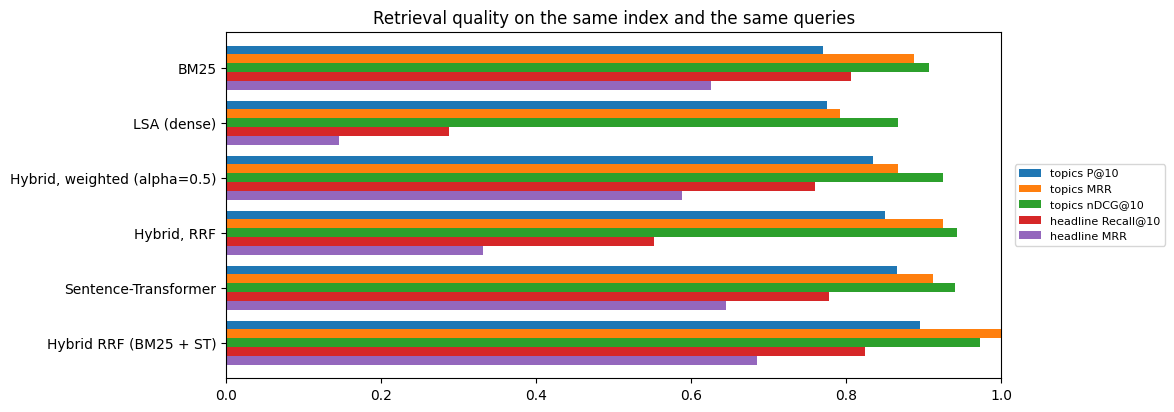

In [23]:
ax = results_table.plot(kind="barh", figsize=(10, 4.5), width=0.8)
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Retrieval quality on the same index and the same queries");

### Retrieval quality

The results are evaluated on the same index and queries, making the methods directly comparable.

**Hybrid RRF (BM25 + Sentence-Transformer)** performs best overall, achieving the highest scores across most metrics. This suggests that BM25's exact-term matching and Sentence-Transformer's semantic understanding complement each other effectively.

Sentence-Transformer alone also performs well, while the LSA-based methods are competitive for topic retrieval but weaker for headline retrieval. Overall, rank-based fusion appears more effective than combining normalized scores directly.

These results are specific to this query set: further evaluation on additional queries would be needed to confirm the observed differences.

## How much weight on the dense side?

The weighted hybrid has one free parameter. Sweeping it on the headline task (alpha = 0 is pure BM25,
alpha = 1 is pure dense):

,Recall@10,MRR
alpha,,
0.0,0.806,0.625
0.1,0.810,0.630
0.2,0.808,0.634
0.3,0.806,0.636
0.5,0.760,0.588
0.7,0.604,0.403
1.0,0.288,0.145


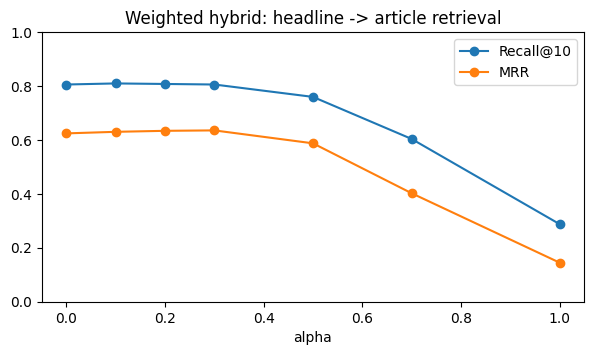

In [24]:
alphas = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
sweep = pd.DataFrame({a: evaluate_known_item(lambda q, a=a: hybrid_weighted(q, a)) for a in alphas}).T
sweep.index.name = "alpha"
ax = sweep.plot(marker="o", figsize=(7, 3.5))
ax.set_ylim(0, 1); ax.set_title("Weighted hybrid: headline -> article retrieval")
sweep.round(3)

On this task the best setting puts most of the weight on BM25 (alpha around 0.1–0.3), for a small gain over BM25 alone: giving the dense side more weight makes things steadily worse. The weak component can still add a little as a tie-breaker, but only with a small weight.

Tuning `alpha` on the same queries that report the final number is optimistic; with more data, one would tune on one set of headlines and report on another.

# 7. Does chunk size matter?

Same headline task, BM25, re-indexed at several chunk sizes (ranking is aggregated per article, so splitting an article into more chunks does not add extra chances).

In [25]:
chunk_results = {}
for size in [200, 500, 1000, 100_000]:
    c = chunk_articles(articles, size=size, overlap=min(50, size // 4))
    index = BM25(c["text"].tolist())
    label = "whole article" if size == 100_000 else f"{size} chars"
    chunk_results[label] = {"chunks": len(c), **evaluate_known_item(index.scores, article_ids=c["article_id"].to_numpy())}
pd.DataFrame.from_dict(chunk_results, orient="index").round(3)

,chunks,Recall@10,MRR
200 chars,95963,0.790,0.621
500 chars,41896,0.806,0.625
1000 chars,26555,0.822,0.643
whole article,19043,0.816,0.645


The differences are small, but consistent with what a headline is: a summary of the whole story. 
Its words are spread over several paragraphs, so larger chunks (or whole articles) collect more of them in one unit, while 200-character chunks split them apart. 
For other queries, such as a precise fact buried in a long article, small chunks can win instead, because the matching passage is not diluted by unrelated text.

For RAG there is a second cost: chunk size decides how much text each retrieved result puts in front of the language model. 
Large chunks retrieve slightly better here but fill the context budget faster (see the RAG notebook).

# 8. Re-ranking the shortlist

A cross-encoder reads the query and a chunk *together* and outputs a relevance score. 
It is far more accurate than comparing two independently computed vectors, and far too slow to score every chunk, so it only re-orders the top candidates of a fast retriever.

In [29]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device="cpu")

def rerank(score_fn, shortlist=30):
    def scored(query):
        candidates = top_k(score_fn(query), shortlist)
        rerank_scores = reranker.predict([(query, chunks["text"][i]) for i in candidates])
        out = np.full(len(chunks), -np.inf)
        out[candidates] = rerank_scores
        return out
    return scored

rerank_results = {}
for name in ["BM25", "Hybrid, RRF"]:
    fn = rerank(methods[name])
    # Keep cross-encoder inference on CPU to avoid MPS memory exhaustion
    reranker.model.to("cpu")

    rerank_results[name + " + rerank"] = {
        **{f"topics {k}": v for k, v in evaluate_topics(fn).items()},
        **{f"headline {k}": v for k, v in evaluate_known_item(fn).items()},
    }
pd.concat([results_table, pd.DataFrame(rerank_results).T.round(3)])

,topics P@10,topics MRR,topics nDCG@10,headline Recall@10,headline MRR
BM25,0.770,0.888,0.907,0.806,0.625
LSA (dense),0.775,0.792,0.867,0.288,0.145
"Hybrid, weighted (alpha=0.5)",0.835,0.867,0.925,0.760,0.588
"Hybrid, RRF",0.850,0.925,0.943,0.552,0.331
Sentence-Transformer,0.865,0.912,0.941,0.778,0.645
Hybrid RRF (BM25 + ST),0.895,1.000,0.972,0.824,0.685
BM25 + rerank,0.875,1.000,0.973,0.828,0.738
"Hybrid, RRF + rerank",0.870,1.000,0.974,0.744,0.661


# Takeaways

- **BM25 is a strong, cheap baseline** and the right tool for identifiers (tickers, company names, figures).
Building it by hand shows it is a sparse matrix product with two well-motivated tweaks over TF-IDF.
- **Dense retrieval adds associations BM25 cannot make** and fails on different queries. A classical dense model like LSA is roughly as good as BM25 for finding on-topic text, but poor at finding one specific article.
- **Hybrid search helps only when both sides are useful for the task.** On topic queries, fusion beats both components: on headline lookup the weak dense side drags it down. Equal-weight fusion (RRF) suffers most, since it gives a weak ranker the same say as a strong one. Weight the components, and measure.
- **Chunk size is a retrieval parameter**, not a formatting detail, and the best value depends on the kind of question.
- **Evaluation design matters as much as the method**: the two evaluations rank the same methods differently, because they reward different behaviours. A single number would have hidden that.